# M5 Forecasting — Exploratory Analysis of Sales

This notebook explores the daily unit sales in `sales_train_evaluation.csv`: 30,490 item–store series covering 1,941 days (2011-01-29 to 2016-05-22). The evaluation file has the same series as the validation file, plus 28 more days.

**Questions**
1. How is the data structured (states → stores → categories → departments → items)?
2. How do total sales trend over time, and where do they come from?
3. What weekly, monthly and yearly patterns show up?
4. How sparse (intermittent) are the individual series?
5. How concentrated are sales across items?
6. Do holidays, events and SNAP days move sales?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 4.5)
pd.set_option("display.float_format", "{:,.2f}".format)

import os
DATA = next(d for d in ("..", ".", "m5-forecasting-accuracy")
            if os.path.isfile(os.path.join(d, "calendar.csv")))   # repo root when run from notebooks/

## 1. Load the data
The sales file is wide (one column per day). Reading the day columns as `int16` keeps it at about 120 MB in memory instead of about 470 MB.

In [2]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
header = pd.read_csv(f"{DATA}/sales_train_evaluation.csv", nrows=0).columns
day_cols = [c for c in header if c.startswith("d_")]

sales = pd.read_csv(
    f"{DATA}/sales_train_evaluation.csv",
    dtype={**{c: "category" for c in id_cols[1:]}, **{d: "int16" for d in day_cols}},
)
calendar = pd.read_csv(f"{DATA}/calendar.csv", parse_dates=["date"])

print(f"sales: {sales.shape[0]:,} series x {len(day_cols):,} days  "
      f"({sales.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory)")
sales.iloc[:5, :12]

sales: 30,490 series x 1,941 days  (120 MB in memory)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,d_5,d_6
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,0,0


In [3]:
# Map day columns (d_1 ... d_1941) to calendar dates
d2date = calendar.set_index("d")["date"]
dates = pd.DatetimeIndex(d2date.loc[day_cols].values)
print("Date range:", dates.min().date(), "→", dates.max().date())

# Matrix of units: rows = series, cols = days
X = sales[day_cols].to_numpy()
print("Missing values in sales:", sales[day_cols].isna().sum().sum())

Date range: 2011-01-29 → 2016-05-22
Missing values in sales: 0


## 2. Hierarchy
There are 3 states, 10 stores, 3 categories, 7 departments and 3,049 distinct products. Every product is listed in every store.

In [4]:
summary = pd.Series({c: sales[c].nunique() for c in id_cols[1:]}, name="unique values")
display(summary.to_frame())

items_per = (sales.drop_duplicates("item_id")
                  .groupby(["cat_id", "dept_id"], observed=True).size()
                  .rename("items").to_frame())
display(items_per)
stores = sales.drop_duplicates("store_id").groupby("state_id", observed=True)["store_id"].apply(lambda x: ", ".join(sorted(map(str, x))))
display(stores.to_frame("stores"))

,unique values
item_id,3049
dept_id,7
cat_id,3
store_id,10
state_id,3


items
cat_id    dept_id           
HOBBIES   HOBBIES_1      416
          HOBBIES_2      149
HOUSEHOLD HOUSEHOLD_1    532
          HOUSEHOLD_2    515
FOODS     FOODS_1        216
          FOODS_2        398
          FOODS_3        823

,stores
state_id,
CA,"CA_1, CA_2, CA_3, CA_4"
TX,"TX_1, TX_2, TX_3"
WI,"WI_1, WI_2, WI_3"


## 3. Total sales over time

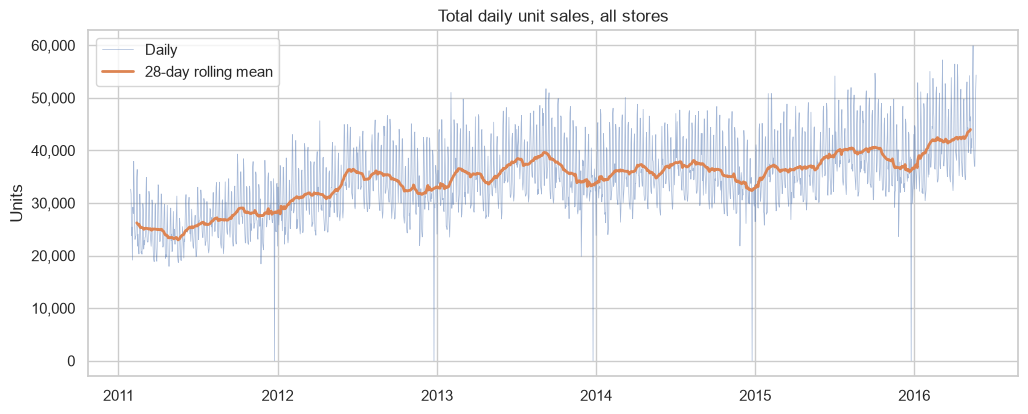

,total units,avg units/day,days observed
2011,8856585,"26,280.67",337
2012,12061837,"32,955.84",366
2013,13135753,"35,988.36",365
2014,13089776,"35,862.40",365
2015,13800811,"37,810.44",365
2016,5982411,"41,835.04",143


In [5]:
total = pd.Series(X.sum(axis=0), index=dates, name="units")

fig, ax = plt.subplots()
ax.plot(total.index, total, lw=0.5, alpha=0.5, label="Daily")
ax.plot(total.index, total.rolling(28, center=True).mean(), lw=2, label="28-day rolling mean")
ax.set(title="Total daily unit sales, all stores", ylabel="Units")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.legend()
plt.show()

yearly = total.groupby(total.index.year).agg(["sum", "mean", "count"])
yearly.columns = ["total units", "avg units/day", "days observed"]
yearly

Sales grow steadily over the five years. Daily totals swing widely from week to week. The near-zero drops each year fall on **Christmas Day**, when the stores are closed:

In [6]:
low_days = total.nsmallest(8).to_frame()
low_days["weekday"] = low_days.index.day_name()
low_days

,units,weekday
2012-12-25,11,Tuesday
2011-12-25,13,Sunday
2015-12-25,14,Friday
2013-12-25,20,Wednesday
2014-12-25,20,Thursday
2011-04-27,17929,Wednesday
2011-04-26,18113,Tuesday
2011-04-28,18145,Thursday


## 4. Breakdown by category, state and store

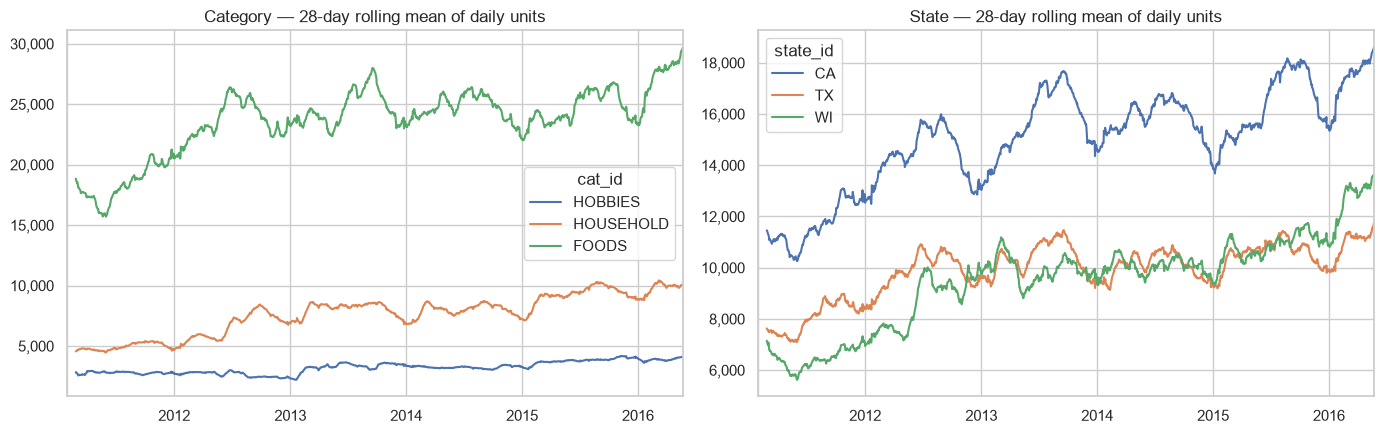

In [7]:
def daily_by(col):
    """Daily units summed by a hierarchy column -> DataFrame (dates x groups)."""
    g = sales.groupby(col, observed=True)[day_cols].sum().T
    g.index = dates
    return g

by_cat = daily_by("cat_id")
by_state = daily_by("state_id")
by_store = daily_by("store_id")
by_dept = daily_by("dept_id")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_cat.rolling(28).mean().plot(ax=axes[0], title="Category — 28-day rolling mean of daily units")
by_state.rolling(28).mean().plot(ax=axes[1], title="State — 28-day rolling mean of daily units")
for ax in axes:
    ax.set_xlabel(""); ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
plt.tight_layout(); plt.show()

In [8]:
share = pd.concat({
    "category": by_cat.sum() / by_cat.values.sum(),
    "state": by_state.sum() / by_state.values.sum(),
    "department": by_dept.sum() / by_dept.values.sum(),
}).rename("share of units").to_frame()
share.style.format("{:.1%}")

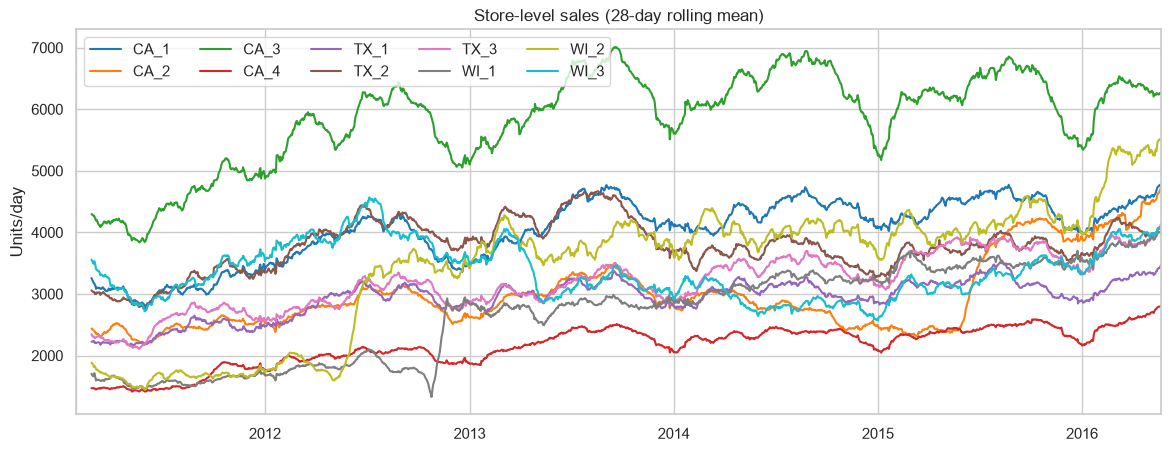

In [9]:
fig, ax = plt.subplots(figsize=(14, 5))
by_store.rolling(28).mean().plot(ax=ax, lw=1.5, cmap="tab10")
ax.set(title="Store-level sales (28-day rolling mean)", ylabel="Units/day", xlabel="")
ax.legend(ncol=5, loc="upper left")
plt.show()

CA_3 is by far the largest store, and CA_4 is the smallest. Several stores show **sudden level shifts**, most likely from remodels, expansions or new product ranges:
- **WI_2** jumps by about 60% in mid-2012, and again in early 2016.
- **WI_1** jumps late in 2012, right after a sharp dip.
- **CA_2** jumps by about 70% in mid-2015.
- **WI_3** drops off in early 2013.

This matters for modelling: for these stores, the history from before the shift doesn't represent how they behave now.

## 5. Seasonality: day of week, month, year

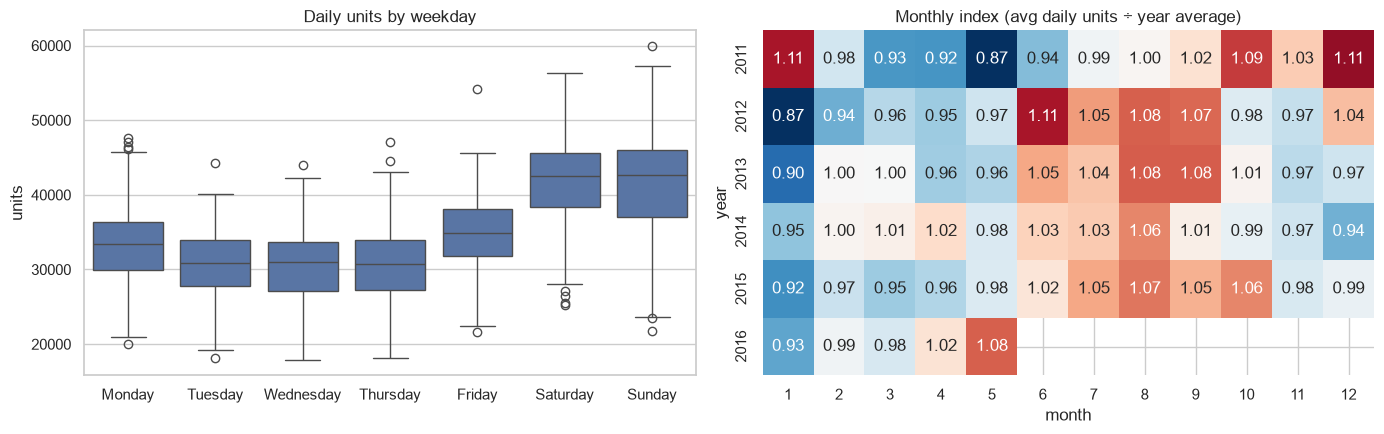

In [10]:
cal = calendar.set_index("date").loc[dates]
df_t = pd.DataFrame({"units": total.values,
                     "weekday": cal["weekday"].values,
                     "month": cal["month"].values,
                     "year": cal["year"].values}, index=dates)
df_t = df_t[~((df_t.index.month == 12) & (df_t.index.day == 25))]   # drop Christmas closures

order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df_t, x="weekday", y="units", order=order, ax=axes[0], color="C0")
axes[0].set(title="Daily units by weekday", xlabel="")

# Month index relative to each year's mean, to remove the growth trend
m = df_t.groupby(["year", "month"])["units"].mean().unstack()
m = m.div(m.mean(axis=1), axis=0)
sns.heatmap(m, annot=True, fmt=".2f", cmap="RdBu_r", center=1, ax=axes[1], cbar=False)
axes[1].set(title="Monthly index (avg daily units ÷ year average)")
plt.tight_layout(); plt.show()

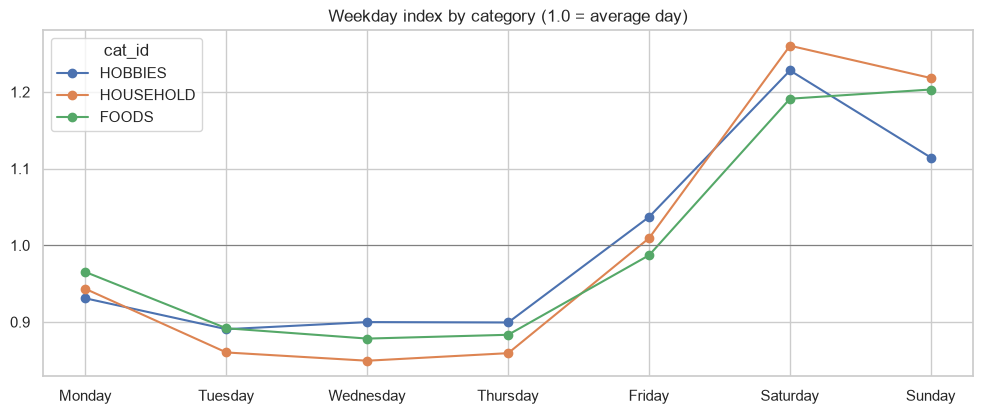

In [11]:
# Weekday profile per category (normalised to each category's mean)
wk = by_cat.copy()
wk["weekday"] = wk.index.day_name()
prof = wk.groupby("weekday").mean().loc[order]
(prof / prof.mean()).plot(marker="o", title="Weekday index by category (1.0 = average day)")
plt.axhline(1, color="grey", lw=0.8); plt.xlabel(""); plt.show()

**Weekly seasonality is strong.** Saturday and Sunday sell about 20–25% above an average day, and Tuesday to Thursday sell about 10–15% below. Household has the biggest Saturday peak. Hobbies falls off on Sunday, while Foods stays high through Sunday.

**Annual seasonality is milder.** There's a summer lift from June to September (about +5–8%), and January is the weakest month (about −5 to −13%). The 2011 row is distorted because data starts on Jan 29, so its January value is only 3 days. 2016 only covers January to May.

## 6. Intermittency — how sparse are individual series?

Share of zero cells overall:              68.0%
Median share of zero days per series (after first sale): 63.3%
Series that start selling after day 1:    77.1%


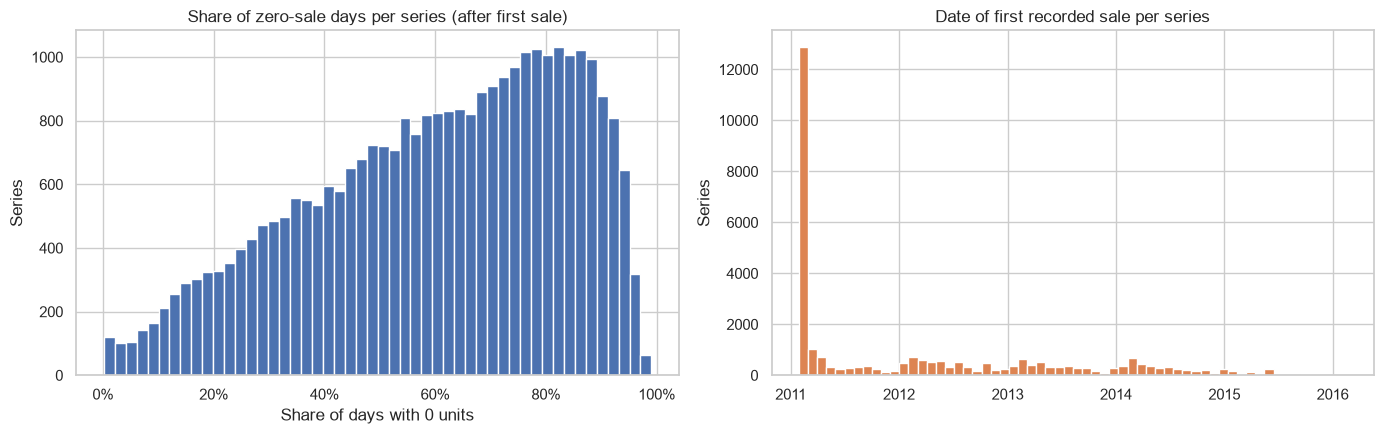

In [12]:
# Ignore leading zeros before an item's first sale (the product wasn't on sale yet)
first_sale = (X > 0).argmax(axis=1)
active_days = X.shape[1] - first_sale
nonzero = (X > 0).sum(axis=1)

zero_share_all = 1 - nonzero / X.shape[1]
zero_share_active = 1 - nonzero / active_days

print(f"Share of zero cells overall:              {(X == 0).mean():.1%}")
print(f"Median share of zero days per series (after first sale): {np.median(zero_share_active):.1%}")
print(f"Series that start selling after day 1:    {(first_sale > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(zero_share_active, bins=50, color="C0")
axes[0].set(title="Share of zero-sale days per series (after first sale)", xlabel="Share of days with 0 units", ylabel="Series")
axes[0].xaxis.set_major_formatter(mtick.PercentFormatter(1))
axes[1].hist(dates[first_sale], bins=60, color="C1")
axes[1].set(title="Date of first recorded sale per series", ylabel="Series")
plt.tight_layout(); plt.show()

,median_zero_share,median_daily_units
cat_id,,
HOBBIES,77.8%,0.31
HOUSEHOLD,69.6%,0.44
FOODS,53.9%,0.93


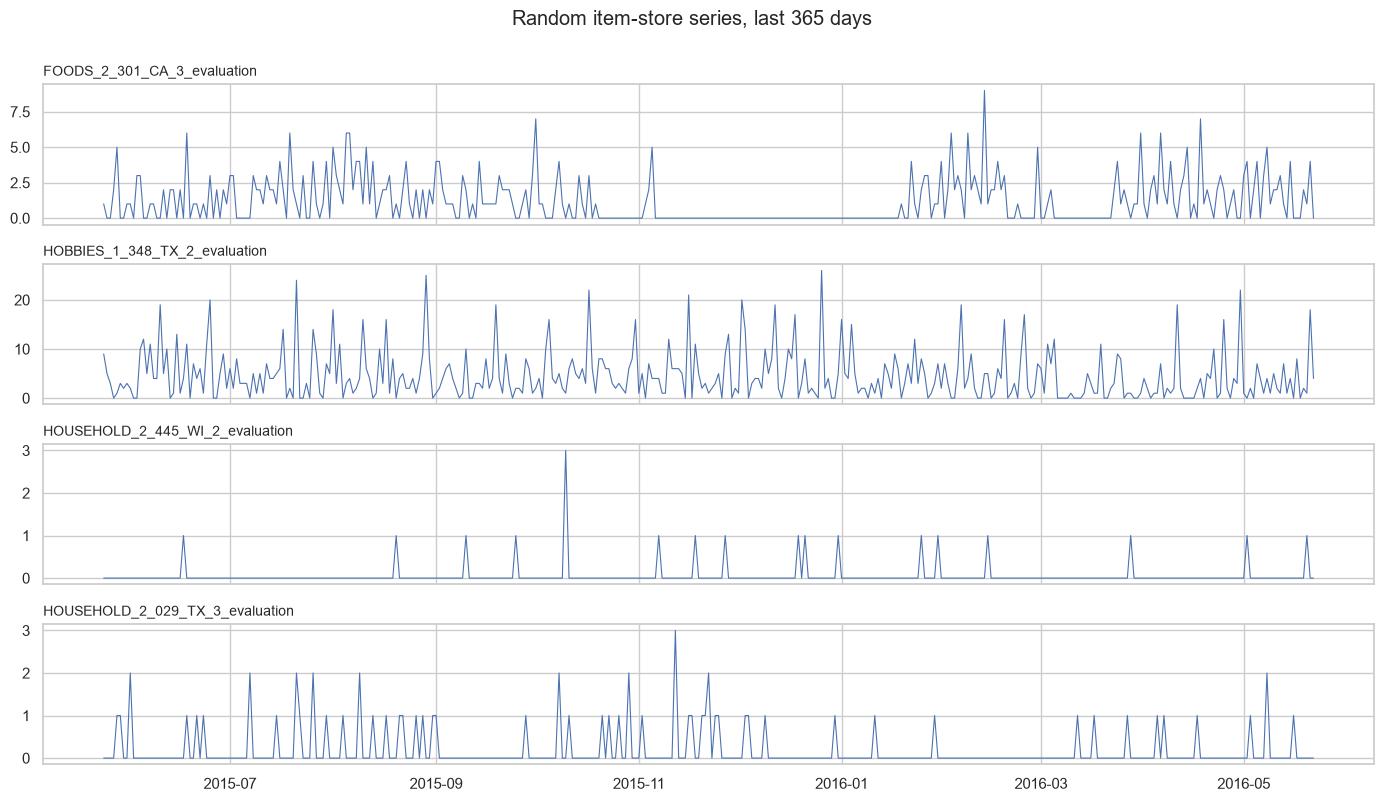

In [13]:
zs = pd.DataFrame({"cat_id": sales["cat_id"], "zero_share": zero_share_active,
                   "mean_daily": X.sum(axis=1) / active_days})
display(zs.groupby("cat_id", observed=True).agg(
    median_zero_share=("zero_share", "median"),
    median_daily_units=("mean_daily", "median")).style.format({"median_zero_share": "{:.1%}", "median_daily_units": "{:.2f}"}))

# A few example series
rng = np.random.default_rng(0)
idx = rng.choice(len(sales), 4, replace=False)
fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
for ax, i in zip(axes, idx):
    ax.plot(dates[-365:], X[i, -365:], lw=0.8)
    ax.set_title(sales["id"].iloc[i], fontsize=10, loc="left")
plt.suptitle("Random item-store series, last 365 days", y=1.0); plt.tight_layout(); plt.show()

Most individual series are **intermittent**: on a typical day, a typical item sells zero units in a given store. Many items also only begin selling partway through the period. Both facts point toward forecasting methods that handle sparse counts well (e.g. Tweedie/Poisson objectives) rather than plain Gaussian error assumptions. They also mean models should be trained on data from after each item's first sale.

## 7. Concentration — which items drive volume?

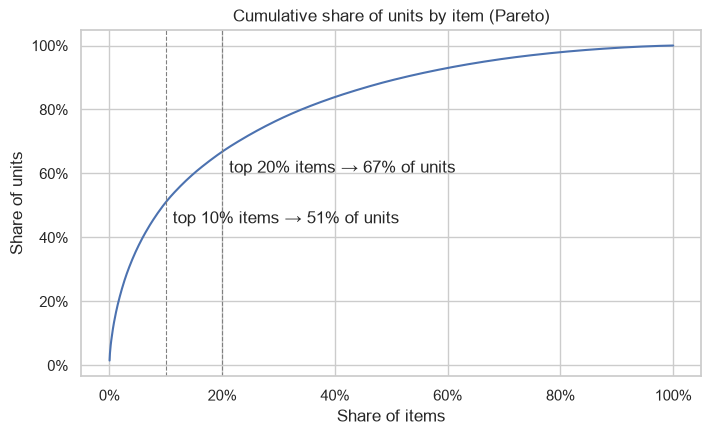

,total units
FOODS_3_090,1017916
FOODS_3_586,932236
FOODS_3_252,573723
FOODS_3_555,497881
FOODS_3_587,402159
FOODS_3_714,402111
FOODS_3_694,395937
FOODS_3_226,368369
FOODS_3_202,300529
FOODS_3_120,290132


In [14]:
item_units = (pd.Series(X.sum(axis=1), name="units")
                .groupby(sales["item_id"].astype(str).values).sum()
                .sort_values(ascending=False))
cum = item_units.cumsum() / item_units.sum()

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum), cum.values)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
for p in [0.1, 0.2]:
    ax.axvline(p, ls="--", c="grey", lw=0.8)
    ax.annotate(f"top {p:.0%} items → {cum.iloc[int(p*len(cum))-1]:.0%} of units", (p, cum.iloc[int(p*len(cum))-1]),
                xytext=(5, -15), textcoords="offset points")
ax.set(title="Cumulative share of units by item (Pareto)", xlabel="Share of items", ylabel="Share of units")
plt.show()

item_units.head(10).to_frame("total units")

## 8. Events, holidays and SNAP days

,mean,count
event_type_1,,
Cultural,-5.9%,37
National,+0.5%,46
No event,+0.5%,1783
Religious,+0.9%,54
Sporting,+1.5%,16


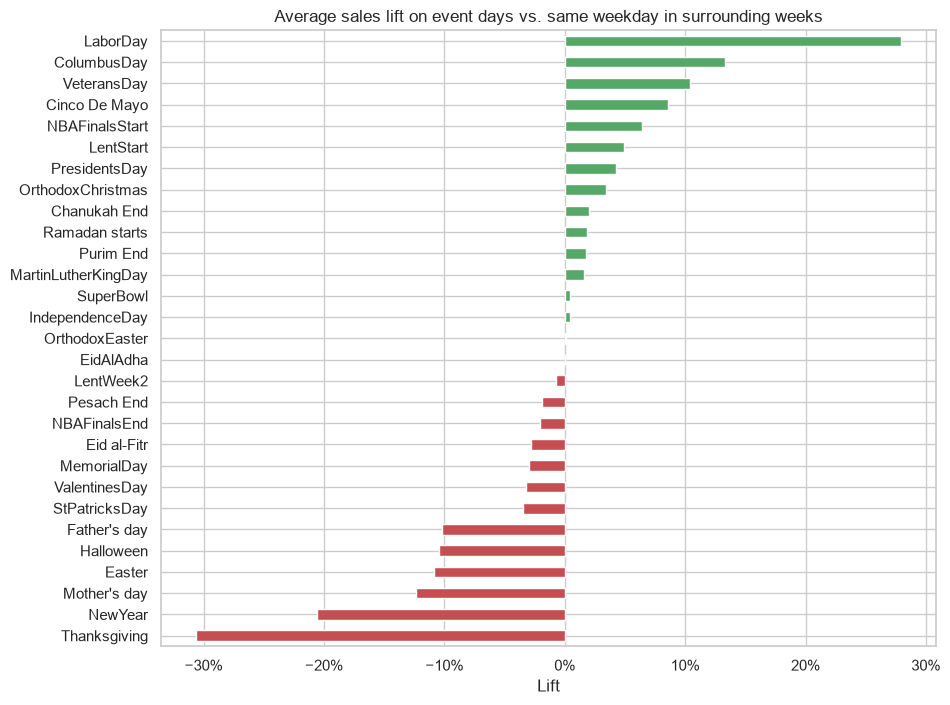

In [15]:
ev = cal[["event_name_1", "event_type_1", "snap_CA", "snap_TX", "snap_WI"]].copy()
ev["units"] = total.values
ev = ev[~((ev.index.month == 12) & (ev.index.day == 25))]

# Baseline = median of the SAME weekday 1-3 weeks before and after (controls for trend AND weekday)
def same_weekday_baseline(s):
    s = s.mask((s.index.month == 12) & (s.index.day == 25))   # don't let closures pollute the baseline
    return pd.concat([s.shift(7 * k) for k in (-3, -2, -1, 1, 2, 3)], axis=1).median(axis=1)

ev["lift"] = ev["units"] / same_weekday_baseline(total).loc[ev.index] - 1

lift_type = ev.groupby(ev["event_type_1"].fillna("No event"))["lift"].agg(["mean", "count"])
display(lift_type.style.format({"mean": "{:+.1%}"}))

top_ev = (ev.dropna(subset=["event_name_1"]).groupby("event_name_1")["lift"].mean().sort_values())
fig, ax = plt.subplots(figsize=(10, 8))
top_ev.plot.barh(ax=ax, color=np.where(top_ev > 0, "C2", "C3"))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set(title="Average sales lift on event days vs. same weekday in surrounding weeks", xlabel="Lift", ylabel="")
plt.show()

Comparing each day with the same weekday in the surrounding weeks takes out both the trend and the weekend effect. Ordinary days come out at roughly 0%, as they should. Against that baseline:
- **Family and stay-at-home holidays reduce volume:** Thanksgiving (about −30%), New Year (about −20%), and Mother's Day, Easter, Halloween and Father's Day (about −10% each).
- **Monday federal holidays increase volume:** Labor Day (about +28%), Columbus Day and Veterans Day (+10% to +13%). People shop on their day off.
- Most other events, including the Super Bowl and most religious events, are within a few percent of normal.

So event effects are specific to each event rather than to each event *type*. A forecasting model should get one feature per event, not just the event type.

In [16]:
# SNAP: food-stamp benefit days, set per state. Compare FOODS sales by state on SNAP vs non-SNAP days.
foods_state = sales[sales["cat_id"] == "FOODS"].groupby("state_id", observed=True)[day_cols].sum().T
foods_state.index = dates

# SNAP days come in a 10-day block each month, so compare SNAP vs non-SNAP days
# of the same weekday within the same month (controls for trend and weekday).
rows = []
for st in ["CA", "TX", "WI"]:
    d = pd.DataFrame({"units": foods_state[st].values, "snap": cal[f"snap_{st}"].values,
                      "ym": dates.to_period("M"), "wd": dates.dayofweek}, index=dates)
    d = d[~((d.index.month == 12) & (d.index.day == 25))]
    g = d.groupby(["ym", "wd", "snap"])["units"].mean().unstack("snap").dropna()
    rows.append({"state": st, "SNAP-day lift (FOODS)": (g[1] / g[0] - 1).mean(),
                 "SNAP days/month": d["snap"].sum() / d["ym"].nunique()})
pd.DataFrame(rows).set_index("state").style.format({"SNAP-day lift (FOODS)": "{:+.1%}", "SNAP days/month": "{:.1f}"})

,SNAP-day lift (FOODS),SNAP days/month
state,,
CA,+10.3%,9.8
TX,+15.9%,9.8
WI,+30.3%,9.8


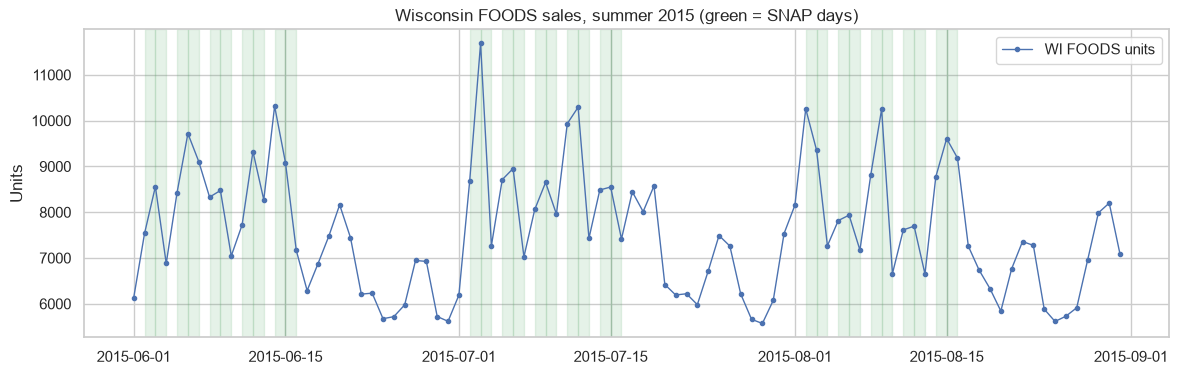

In [17]:
fig, ax = plt.subplots(figsize=(14, 4))
window = slice("2015-06-01", "2015-08-31")
s = foods_state.loc[window, "WI"]
ax.plot(s.index, s, marker=".", lw=1, label="WI FOODS units")
snap_days = cal.loc[window].query("snap_WI == 1").index
for d in snap_days:
    ax.axvspan(d, d + pd.Timedelta(days=1), color="C2", alpha=0.15)
ax.set(title="Wisconsin FOODS sales, summer 2015 (green = SNAP days)", ylabel="Units"); ax.legend()
plt.show()

## 9. Key takeaways

| Finding | Implication for forecasting |
|---|---|
| Sales grow over 2011–2016; Christmas Day is ~0 (stores closed) | Model the trend; treat Dec 25 as a known closure |
| FOODS is ~2/3 of units; CA is the biggest state | Errors on FOODS and CA dominate aggregate accuracy |
| Store-level structural breaks (sudden level jumps) | Weight recent history more heavily; consider per-store models |
| Strong weekly seasonality (weekend peak ~+20–25%), milder summer lift | Day-of-week features are essential; add month features |
| Most item-store series are intermittent and many start late | Use count-friendly losses (Tweedie/Poisson); drop pre-launch zeros |
| Top 10% of items = ~51% of units; top 20% = ~67% | Top items deserve extra attention; long tail is mostly noise |
| Thanksgiving/New Year cut sales 20–30%; Monday holidays (Labor Day) lift them | Use one feature per event, not just event type |
| SNAP days lift FOODS by ~10% (CA), ~16% (TX), ~30% (WI) | Include SNAP flags per state, especially for FOODS |

**Next steps:** join `sell_prices.csv` to study price elasticity and revenue, and build a simple seasonal-naive baseline to benchmark models against.